# Viperr
### Сравнительный анализ творчества Kai Angel и 9mice

**Цель:** исследовать релизную активность, изменение продолжительности треков и стратегии коллабораций двух исполнителей, включая их ранние псевдонимы.

**Гипотезы:** сокращается ли длительность композиций со временем; различаются ли стратегии выпуска и сотрудничества артистов; связаны ли длительность и коллаборации с успехом в чартах.

**Источники:** Apple iTunes Search API (каталог US) и Kworb (архив чартов Spotify). Для чартов рассматривались BY, KZ, UA, LV, EE и LT - страны, представленные в истории чартов обоих артистов или одного из них.

## 1. Библиотеки и настройки

In [1]:
import requests
import time
import re

import pandas as pd
import plotly.express as px

from statistics import median
from IPython.display import display

lookup_url = "https://itunes.apple.com/lookup"
from pathlib import Path

artist_colors = {
    "Kai Angel": "#FF2400",
    "9mice": "#080B16"
}

duration_colors = {
    "ultra_short": "#7C3AED",
    "short": "#A78BFA",
    "medium": "#3B82F6",
    "long": "#F59E0B"
}

# False — собрать данные заново; True — использовать обе сохранённые таблицы, если они есть.
USE_SAVED_DATA = True
load_saved = USE_SAVED_DATA and Path("albums.csv").exists() and Path("tracks_raw.csv").exists()


## 2. Сбор данных
### Выбор музыкальных профилей

В ходе предварительного поиска обнаружены одноимённые артисты с разными ID. Проверялись их релизы и оставили следующие профили. Ранние псевдонимы объединяли с современными; принадлежность дополнительных профилей и полнота каталогов требуют отдельной проверки.

In [2]:
artists = {
    "Kai Angel": [1617297110, 1692581180],
    "zavet": [1461760296],
    "9mice": [1593955534],
    "димайс": [1485237396, 1488968572]
}

artist_mapping = {
    "Kai Angel": "Kai Angel",
    "zavet": "Kai Angel",
    "9mice": "9mice",
    "димайс": "9mice"
}


### Функции получения релизов и треков

In [3]:
def get_albums(artist_id):
    params = {
        "id": artist_id,
        "entity": "album",
        "country": "US",
        "limit": 200
    }

    response = requests.get(
        lookup_url, params=params, timeout=30
    )
    response.raise_for_status()

    data = response.json()

    albums = []

    for item in data["results"]:
        if item.get("wrapperType") == "collection":
            albums.append(item)

    return albums

def get_tracks(collection_id):
    params = {
        "id": collection_id,
        "entity": "song",
        "country": "US",
        "limit": 200
    }

    response = requests.get(
        lookup_url, params=params, timeout=30
    )
    response.raise_for_status()

    data = response.json()

    songs = []

    for item in data["results"]:
        if item.get("kind") == "song":
            songs.append(item)

    return songs


In [4]:
def classify_duration(duration):
    if duration < 90:
        return "ultra_short"
    elif duration < 120:
        return "short"
    elif duration < 180:
        return "medium"
    else:
        return "long"


### Получение и сохранение списка релизов

In [5]:
if load_saved:
    albums_df = pd.read_csv("albums.csv")
    all_albums = albums_df.to_dict("records")
else:
    all_albums = []

    for alias, ids in artists.items():
        for artist_id in ids:

            albums = get_albums(artist_id)

            for album in albums:
                album_info = {
                    "artist": artist_mapping[alias],
                    "alias": alias,
                    "artist_id": artist_id,
                    "album_id": album["collectionId"],
                    "album_name": album["collectionName"],
                    "release_date": album["releaseDate"],
                    "track_count": album["trackCount"]
                }

                all_albums.append(album_info)

            print(alias, artist_id, "Релизов:", len(albums))

            time.sleep(3)
    albums_df = pd.DataFrame(all_albums)
    albums_df.to_csv("albums.csv", index=False, encoding="utf-8-sig")

print("Релизов в таблице:", len(albums_df))
display(albums_df.head())


Релизов в таблице: 65


,artist,alias,artist_id,album_id,album_name,release_date,track_count
0,Kai Angel,Kai Angel,1617297110,6773684881,Pretty Girls - Single,2026-05-29T07:00:00Z,1
1,Kai Angel,Kai Angel,1617297110,1678069965,Marilyn Manson,2023-03-24T07:00:00Z,11
2,Kai Angel,Kai Angel,1617297110,6808162752,Shh...,2026-09-04T07:00:00Z,14
3,Kai Angel,Kai Angel,1617297110,1889509006,Limousine Music - Single,2026-04-10T07:00:00Z,1
4,Kai Angel,Kai Angel,1617297110,6810597974,Shh!,2026-09-11T07:00:00Z,14


### Функция сбора дискографии

Кеш не позволяет повторно загружать один и тот же совместный релиз. Обработка исключений сохраняет список релизов, которые не удалось получить.

In [6]:
def collect_discography(albums):

    all_tracks = []
    cache = {}
    errors = []

    for album in albums:

        album_id = album["album_id"]

        if album_id not in cache:
            try:
                cache[album_id] = get_tracks(album_id)
                time.sleep(3)

            except requests.RequestException as error:
                print("Ошибка:", album["album_name"])
                errors.append(album)
                continue

        songs = cache[album_id]

        for track in songs:

            duration = track["trackTimeMillis"] / 1000

            track_info = {
                "artist": album["artist"],
                "alias": album["alias"],
                "track_id": track["trackId"],
                "track_name": track["trackName"],
                "track_artists": track["artistName"],
                "album_id": album_id,
                "album_name": album["album_name"],
                "release_date": track.get("releaseDate"),
                "album_release_date": album["release_date"],
                "duration_sec": duration,
                "duration_category": classify_duration(duration),
                "genre": track.get("primaryGenreName"),
                "explicitness": track.get("trackExplicitness"),
                "track_number": track.get("trackNumber"),
                "track_url": track.get("trackViewUrl")
            }

            all_tracks.append(track_info)

        print(album["album_name"], "—", len(songs), "треков")

    return all_tracks, errors


In [7]:
if load_saved:
    tracks_df = pd.read_csv("tracks_raw.csv")
    print("Используем ранее сохранённый датасет.")
else:
    all_tracks, errors = collect_discography(all_albums)
    tracks_df = pd.DataFrame(all_tracks)
    if tracks_df.empty:
        raise ValueError("Не удалось получить ни одного трека. Проверь подключение к API.")
    tracks_df.to_csv("tracks_raw.csv", index=False, encoding="utf-8-sig")
    print("Не удалось загрузить релизов:", len(errors))
    if errors:
        pd.DataFrame(errors).to_csv("failed_albums.csv", index=False, encoding="utf-8-sig")

print("Размер исходной таблицы:", tracks_df.shape)
display(tracks_df.head())


Используем ранее сохранённый датасет.
Размер исходной таблицы: (261, 15)


,artist,alias,track_id,track_name,track_artists,album_id,album_name,release_date,album_release_date,duration_sec,duration_category,genre,explicitness,track_number,track_url
0,Kai Angel,Kai Angel,6773685136,Pretty Girls,Kai Angel,6773684881,Pretty Girls - Single,2026-05-29T12:00:00Z,2026-05-29T07:00:00Z,177.857,medium,Indie Pop,explicit,1,https://music.apple.com/us/album/pretty-girls/...
1,Kai Angel,Kai Angel,1678070296,Marilyn Manson,Kai Angel,1678069965,Marilyn Manson,2023-03-24T12:00:00Z,2023-03-24T07:00:00Z,144.000,medium,Hip-Hop/Rap,explicit,1,https://music.apple.com/us/album/marilyn-manso...
2,Kai Angel,Kai Angel,1678070297,Stupid,Kai Angel,1678069965,Marilyn Manson,2023-03-24T12:00:00Z,2023-03-24T07:00:00Z,135.000,medium,Hip-Hop/Rap,explicit,2,https://music.apple.com/us/album/stupid/167806...
3,Kai Angel,Kai Angel,1678070298,Prada Party,Kai Angel,1678069965,Marilyn Manson,2023-03-24T12:00:00Z,2023-03-24T07:00:00Z,124.235,medium,Hip-Hop/Rap,explicit,3,https://music.apple.com/us/album/prada-party/1...
4,Kai Angel,Kai Angel,1678070299,Ss16 Cyclops,Kai Angel,1678069965,Marilyn Manson,2023-03-24T12:00:00Z,2023-03-24T07:00:00Z,140.160,medium,Hip-Hop/Rap,explicit,4,https://music.apple.com/us/album/ss16-cyclops/...


## 3. Проверка и очистка данных

Исходные записи сохраняем без изменения. Проверяем пропуски, число уникальных идентификаторов и полноту сбора релизов.

In [8]:
print("Уникальных track_id:", tracks_df["track_id"].nunique())
display(tracks_df["alias"].value_counts())
display(tracks_df["duration_category"].value_counts())
display(tracks_df.isna().sum())


Уникальных track_id: 231


alias
Kai Angel    137
9mice         82
zavet         39
димайс         3
Name: count, dtype: int64

duration_category
medium         163
short           56
ultra_short     22
long            20
Name: count, dtype: int64

artist                0
alias                 0
track_id              0
track_name            0
track_artists         0
album_id              0
album_name            0
release_date          0
album_release_date    0
duration_sec          0
duration_category     0
genre                 0
explicitness          0
track_number          0
track_url             0
dtype: int64

In [9]:
album_check = tracks_df.groupby("album_id")[
    "track_id"
].nunique().reset_index()

album_check = album_check.rename(
    columns={"track_id": "collected_tracks"}
)

album_check = albums_df.merge(
    album_check,
    on="album_id",
    how="left"
)

album_check["collected_tracks"] = (
    album_check["collected_tracks"].fillna(0)
)

album_check["difference"] = (
    album_check["track_count"] -
    album_check["collected_tracks"]
)

display(album_check[album_check["difference"] != 0][[
    "alias",
    "album_name",
    "track_count",
    "collected_tracks",
    "difference"
]])


,alias,album_name,track_count,collected_tracks,difference


### Повторы и коллаборации

Один track_id может быть возвращён для обоих исполнителей. Удаляем такие повторы, затем определяем участников с учётом поля исполнителя и отметок feat. в названии.

In [10]:
duplicates = tracks_df[tracks_df.duplicated(subset=["track_id"], keep=False)]
display(duplicates[["track_id", "track_name", "track_artists", "artist"]].sort_values("track_id").head(10))

unique_tracks = tracks_df.drop_duplicates(subset=["track_id"]).copy()
print("Исходных записей:", len(tracks_df))
print("Уникальных track_id:", len(unique_tracks))


,track_id,track_name,track_artists,artist
55,1690153886,THRILLEЯ,Kai Angel & 9mice,Kai Angel
233,1690153886,THRILLEЯ,Kai Angel & 9mice,9mice
187,1718731021,STAY WITH ME,9mice & Kai Angel,9mice
80,1718731021,STAY WITH ME,9mice & Kai Angel,Kai Angel
237,1767963479,Cyber Is Dead Interlude,9mice & Kai Angel,9mice
59,1767963479,Cyber Is Dead Interlude,9mice & Kai Angel,Kai Angel
60,1767963482,Fountainebleu,9mice & Kai Angel,Kai Angel
238,1767963482,Fountainebleu,9mice & Kai Angel,9mice
239,1767963484,Phoenix,9mice & Kai Angel,9mice
61,1767963484,Phoenix,9mice & Kai Angel,Kai Angel


Исходных записей: 261
Уникальных track_id: 231


In [11]:
alias_mapping = {
    "kai angel": "Kai Angel",
    "zavet": "Kai Angel",
    "9mice": "9mice",
    "димайс": "9mice"
}
def get_participants(track_artists, track_name):

    artists_text = track_artists

    features = re.findall(
        r"\(feat\.\s*(.*?)\)",
        track_name,
        flags=re.IGNORECASE
    )

    for feature in features:
        artists_text += ", " + feature

    names = re.split(r"[,&]", artists_text)

    participants = []

    for name in names:
        name = name.strip().lower()

        if not name:
            continue

        name = alias_mapping.get(name, name)

        if name not in participants:
            participants.append(name)

    return participants

def classify_collaboration(participants):

    has_kai = "Kai Angel" in participants
    has_mice = "9mice" in participants

    if has_kai and has_mice:
        if len(participants) == 2:
            return "rr"
        else:
            return "rr_collab"

    elif has_kai or has_mice:
        if len(participants) == 1:
            return "solo"
        else:
            return "solo_collab"

    else:
        return "unknown"

def normalize_title(title):

    title = re.sub(
        r"\(feat\.\s*.*?\)",
        "",
        title,
        flags=re.IGNORECASE
    )

    return title.strip().lower()


In [12]:
unique_tracks["participants"] = unique_tracks.apply(
    lambda row: get_participants(row["track_artists"], row["track_name"]),
    axis=1
)
unique_tracks["collab_type"] = unique_tracks["participants"].apply(classify_collaboration)
unique_tracks["normalized_title"] = unique_tracks["track_name"].apply(normalize_title)
unique_tracks["participants_key"] = unique_tracks["participants"].apply(
    lambda names: " | ".join(sorted(names))
)

possible_duplicates = unique_tracks[
    unique_tracks.duplicated(subset=["normalized_title", "participants_key"], keep=False)
]
display(possible_duplicates.sort_values("normalized_title")[
    ["track_id", "track_name", "album_name", "participants", "duration_sec", "release_date"]
])


,track_id,track_name,album_name,participants,duration_sec,release_date
58,1729200805,DANCE LIKE U IN PAIN,DANCE LIKE U IN PAIN - Single,[Kai Angel],87.692,2024-02-05T12:00:00Z
122,1736963354,DANCE LIKE U IN PAIN,GOD SYSTEM,[Kai Angel],87.692,2024-02-05T12:00:00Z
23,6808163852,Limousine Music,Shh...,[Kai Angel],188.000,2026-04-10T12:00:00Z
26,1889509012,Limousine Music,Limousine Music - Single,[Kai Angel],188.000,2026-04-10T12:00:00Z
54,1784463001,Madam,Madam - Single,[Kai Angel],142.222,2024-12-13T12:00:00Z
106,1836428121,Madam,damage,[Kai Angel],142.222,2024-12-13T12:00:00Z
181,1694212880,NEW-YORK,SOLOIST,[9mice],87.054,2021-12-28T12:00:00Z
232,1593961214,New-York,New-York - Single,[9mice],87.429,2021-11-07T12:00:00Z
0,6773685136,Pretty Girls,Pretty Girls - Single,[Kai Angel],177.857,2026-05-29T12:00:00Z
18,6808163349,Pretty Girls,Shh...,[Kai Angel],177.857,2026-05-29T12:00:00Z


### Объединение повторных изданий

Словарь содержит пары ID, отобранные вручную при предварительном сравнении названий, состава исполнителей, дат и длительности. Две версии NEW-YORK пока оставлены отдельно, поскольку их даты и длительность различаются. Одинаковый `song_id` означает, что записи относятся к одной композиции.

In [13]:
duplicate_mapping = {
    1846155982: 1746458437,  # Your Love
    1719946185: 1702936778,  # ГЕРОИНЯ
    1736963354: 1729200805,  # DANCE LIKE U IN PAIN
    6808163852: 1889509012,  # Limousine Music
    1836428121: 1784463001,  # Madam
    6808163349: 6773685136,  # Pretty Girls
    1736963700: 1734236534,  # SHOW OFF
    1666528947: 1666528727,  # Stop!
    1836428128: 1829823450   # welcome to forever
}
# STAY WITH ME — совпадают авторство, длительность и дата.
duplicate_mapping[1719945458] = 1718731021

unique_tracks["song_id"] = (
    unique_tracks["track_id"].replace(duplicate_mapping)
)

tracks_clean = (
    unique_tracks
    .sort_values(["release_date", "album_release_date"])
    .drop_duplicates(subset=["song_id"])
    .reset_index(drop=True)
)

print("Количество композиций:", len(tracks_clean))

track_mapping = unique_tracks[["track_id", "song_id", "album_id", "album_name"]]
track_mapping.to_csv("track_mapping.csv", index=False, encoding="utf-8-sig")


Количество композиций: 221


## 4. Подготовка признаков для анализа

Типы сотрудничества: `solo` - сольный трек; `rr` - оба артиста без других участников; `rr_collab` - оба артиста и сторонние исполнители; `solo_collab` - один из двух артистов и сторонние исполнители. `unknown` - техническая категория для проверки.

В таблице `artist_tracks` совместные треки учитывались у каждого участника.

In [14]:
artist_tracks = tracks_clean.explode("participants").copy()
artist_tracks = artist_tracks[
    artist_tracks["participants"].isin(["Kai Angel", "9mice"])
].copy()
artist_tracks = artist_tracks.rename(columns={
    "artist": "source_artist",
    "alias": "source_alias",
    "participants": "artist"
})
artist_tracks = artist_tracks.drop_duplicates(
    subset=["artist", "song_id"]
).reset_index(drop=True)


print("Композиции по исполнителям:")
display(artist_tracks["artist"].value_counts())
display(pd.crosstab(artist_tracks["artist"], artist_tracks["collab_type"]))


Композиции по исполнителям:


artist
Kai Angel    171
9mice         82
Name: count, dtype: int64

collab_type,rr,rr_collab,solo,solo_collab
artist,,,,
9mice,30,2,44,6
Kai Angel,30,2,133,6


In [15]:
def classify_era(year):
    if year < 2023:
        return "early"
    elif year <= 2024:
        return "viperr"
    else:
        return "post_viperr"

for table in [tracks_clean, artist_tracks]:
    table["release_date"] = pd.to_datetime(table["release_date"], utc=True)
    table["year"] = table["release_date"].dt.year
    table["era"] = table["year"].apply(classify_era)


Периоды заданы по календарным годам для сравнения, а не как точная дата распада дуэта.

In [16]:
print("Уникальных композиций:", tracks_clean["song_id"].nunique())
display(tracks_clean["collab_type"].value_counts())
display(tracks_clean[tracks_clean["collab_type"] == "unknown"][
    ["track_name", "track_artists", "participants"]
])

tracks_clean.to_csv("tracks_clean.csv", index=False, encoding="utf-8-sig")
artist_tracks.to_csv("artist_tracks.csv", index=False, encoding="utf-8-sig")


Уникальных композиций: 221


collab_type
solo           177
rr              30
solo_collab     12
rr_collab        2
Name: count, dtype: int64

,track_name,track_artists,participants


## 5. Анализ данных
### Сравнение альбомов и EP

Категории длительности: ultra_short - до 90 сек. (не включительно), short - от 90 до 120 сек. (не включительно), medium - от 120 до 180 сек. (не включительно), long - от 180 сек.

Использовался исходный датасет, чтобы сохранить все треки конкретного альбома, включая выпущенные ранее синглы.

In [17]:
def analyze_album(tracks):
    durations = []

    categories = {
        "ultra_short": 0,
        "short": 0,
        "medium": 0,
        "long": 0
    }

    for track in tracks:
        duration = track["duration_sec"]
        durations.append(duration)

        category = classify_duration(duration)
        categories[category] += 1

    total = len(durations)

    if total == 0:
        return {}

    result = {
        "track_count": total,
        "mean_duration": round(sum(durations) / total, 2),
        "median_duration": round(median(durations), 2),
        "min_duration": min(durations),
        "max_duration": max(durations)
    }

    for category, count in categories.items():
        result[category + "_count"] = count
        result[category + "_percentage"] = round(count / total * 100, 2)

    return result


In [18]:
selected_albums = albums_df[
    (albums_df["track_count"] > 1) &
    (~albums_df["album_name"].str.endswith(" - Single"))
].copy()

selected_albums = selected_albums.drop_duplicates(
    subset=["album_id"]
)

selected_albums = selected_albums.sort_values("release_date")

display(selected_albums[[
    "album_name",
    "release_date",
    "track_count"
]])


,album_name,release_date,track_count
38,velvet heaven,2020-07-03T07:00:00Z,9
28,nights before gotika - EP,2021-02-05T08:00:00Z,5
31,gotika,2021-10-21T07:00:00Z,13
43,SOLOIST,2021-12-28T08:00:00Z,7
16,kAiCoRe - EP,2022-07-01T07:00:00Z,5
5,HEAVY METAL - EP,2023-02-17T08:00:00Z,6
1,Marilyn Manson,2023-03-24T07:00:00Z,11
6,ANGEL MAY CRY,2023-07-07T07:00:00Z,7
49,ORPHEUS,2023-12-08T08:00:00Z,15
21,GOD SYSTEM,2024-03-22T07:00:00Z,17


In [19]:
album_results = {}

for index, album in selected_albums.iterrows():

    album_id = album["album_id"]
    album_name = album["album_name"]
    year = album["release_date"][:4]

    album_tracks = tracks_df[
        tracks_df["album_id"] == album_id
    ].drop_duplicates(subset=["track_id"])

    label = f'{year} — {album_name}'

    album_results[label] = analyze_album(
        album_tracks.to_dict("records")
    )

comparison = pd.DataFrame(album_results).T

display(comparison)

comparison.to_csv(
    "album_comparison.csv",
    encoding="utf-8-sig"
)

,track_count,mean_duration,median_duration,min_duration,max_duration,ultra_short_count,ultra_short_percentage,short_count,short_percentage,medium_count,medium_percentage,long_count,long_percentage
2020 — velvet heaven,9.0,148.25,147.00,113.625,202.873,0.0,0.00,1.0,11.11,7.0,77.78,1.0,11.11
2021 — nights before gotika - EP,5.0,132.93,135.27,122.057,143.694,0.0,0.00,0.0,0.00,5.0,100.00,0.0,0.00
2021 — gotika,13.0,146.59,145.55,125.793,163.184,0.0,0.00,0.0,0.00,13.0,100.00,0.0,0.00
2021 — SOLOIST,7.0,98.79,96.83,48.968,141.046,3.0,42.86,1.0,14.29,3.0,42.86,0.0,0.00
2022 — kAiCoRe - EP,5.0,126.25,133.33,101.793,140.282,0.0,0.00,2.0,40.00,3.0,60.00,0.0,0.00
2023 — HEAVY METAL - EP,6.0,137.47,138.58,104.698,169.500,0.0,0.00,1.0,16.67,5.0,83.33,0.0,0.00
2023 — Marilyn Manson,11.0,128.52,124.23,107.615,159.000,0.0,0.00,4.0,36.36,7.0,63.64,0.0,0.00
2023 — ANGEL MAY CRY,7.0,130.75,129.60,111.625,144.000,0.0,0.00,1.0,14.29,6.0,85.71,0.0,0.00
2023 — ORPHEUS,15.0,132.78,128.01,88.379,184.318,1.0,6.67,3.0,20.00,10.0,66.67,1.0,6.67
2024 — GOD SYSTEM,17.0,144.64,115.39,87.692,657.320,2.0,11.76,9.0,52.94,5.0,29.41,1.0,5.88


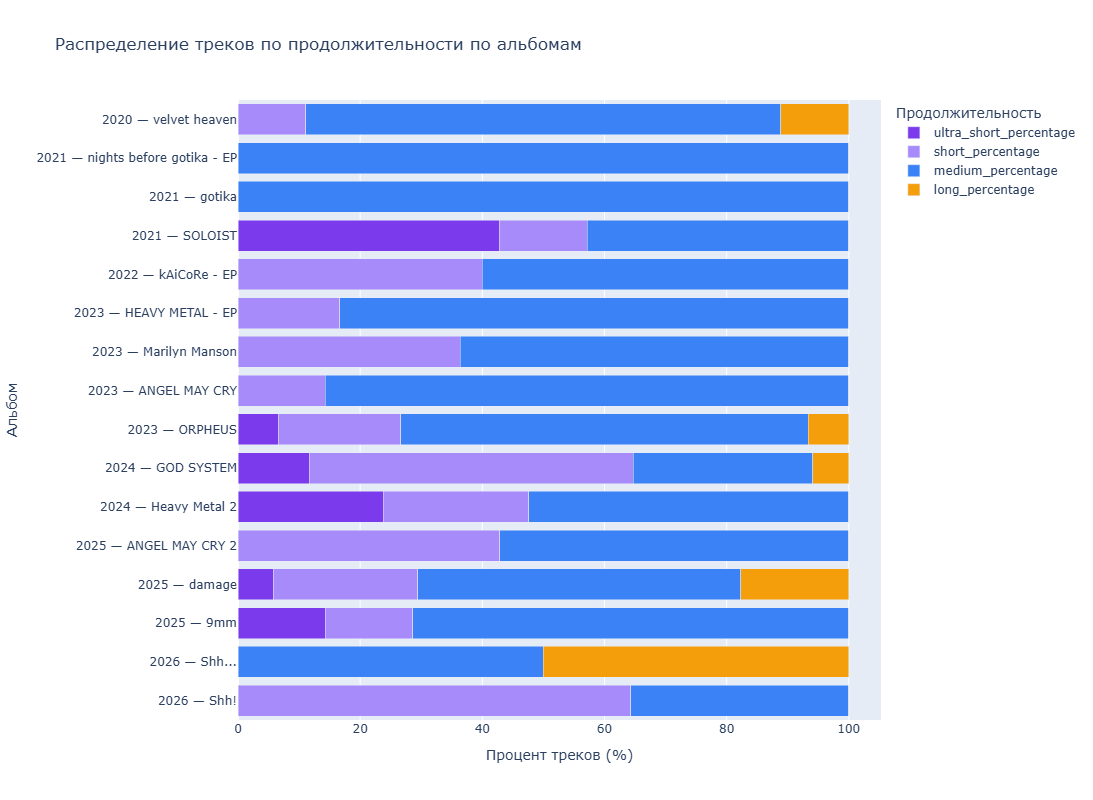

In [20]:
duration_distribution = comparison[[
    "ultra_short_percentage",
    "short_percentage",
    "medium_percentage",
    "long_percentage"
]]

fig = px.bar(
    duration_distribution,
    orientation="h",
    barmode="stack",
    title="Распределение треков по продолжительности по альбомам",
    labels={
        "value": "Процент треков (%)",
        "index": "Альбом",
        "variable": "Продолжительность"
    },
    color_discrete_sequence=list(duration_colors.values())
)

fig.update_layout(height=800)
fig.update_yaxes(autorange="reversed")
fig.show()


### Релизная активность по годам

,year,artist,track_count
0,2019,9mice,1
1,2019,Kai Angel,3
2,2020,9mice,1
3,2020,Kai Angel,9
4,2021,9mice,8
5,2021,Kai Angel,21
6,2022,9mice,1
7,2022,Kai Angel,10
8,2023,9mice,25
9,2023,Kai Angel,32


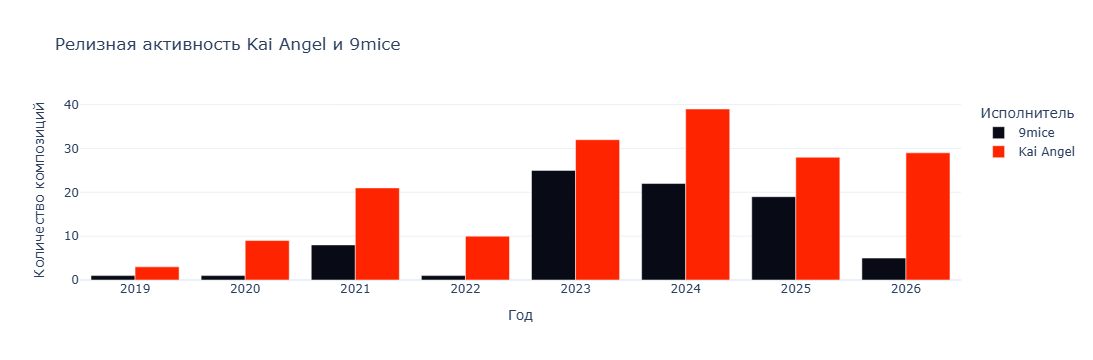

In [21]:
yearly_activity = (
    artist_tracks
    .groupby(["year", "artist"])["song_id"]
    .nunique()
    .reset_index(name="track_count")
)

display(yearly_activity)

fig = px.bar(
    yearly_activity,
    x="year",
    y="track_count",
    color="artist",
    barmode="group",
    title="Релизная активность Kai Angel и 9mice",
    labels={
        "year": "Год",
        "track_count": "Количество композиций",
        "artist": "Исполнитель"
    },
   color_discrete_map=artist_colors,
    template="plotly_white"
)

fig.show()


### Эволюция продолжительности треков

,year,artist,mean,median,count
0,2019,9mice,123.429000,123.4290,1
1,2019,Kai Angel,151.900000,152.7980,3
2,2020,9mice,149.061000,149.0610,1
3,2020,Kai Angel,148.246333,147.0000,9
4,2021,9mice,97.372125,92.1320,8
5,2021,Kai Angel,141.873381,142.4520,21
6,2022,9mice,164.571000,164.5710,1
7,2022,Kai Angel,134.242400,134.9165,10
8,2023,9mice,136.053760,134.0870,25
9,2023,Kai Angel,132.293313,129.0890,32


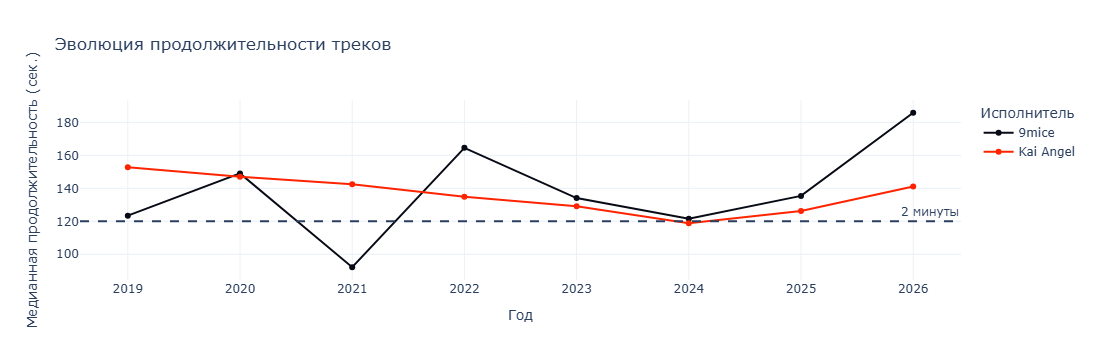

In [22]:
yearly_duration = (
    artist_tracks
    .groupby(["year", "artist"])["duration_sec"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

display(yearly_duration)

fig = px.line(
    yearly_duration,
    x="year",
    y="median",
    color="artist",
    markers=True,
    hover_data=["count", "mean"],
    title="Эволюция продолжительности треков",
    labels={
        "year": "Год",
        "median": "Медианная продолжительность (сек.)",
        "artist": "Исполнитель"
    },
    color_discrete_map=artist_colors,
    template="plotly_white"
)

fig.add_hline(
    y=120,
    line_dash="dash",
    annotation_text="2 минуты"
)

fig.show()


### Эволюция стратегии коллабораций

In [23]:
collab_stats = (
    artist_tracks
    .groupby(["artist", "era", "collab_type"])["song_id"]
    .nunique()
    .reset_index(name="track_count")
)

collab_stats["percentage"] = (
    collab_stats["track_count"] /
    collab_stats.groupby(["artist", "era"])["track_count"].transform("sum")
    * 100
).round(2)

display(collab_stats)

,artist,era,collab_type,track_count,percentage
0,9mice,early,solo,9,81.82
1,9mice,early,solo_collab,2,18.18
2,9mice,post_viperr,solo,22,91.67
3,9mice,post_viperr,solo_collab,2,8.33
4,9mice,viperr,rr,30,63.83
5,9mice,viperr,rr_collab,2,4.26
6,9mice,viperr,solo,13,27.66
7,9mice,viperr,solo_collab,2,4.26
8,Kai Angel,early,solo,39,90.70
9,Kai Angel,early,solo_collab,4,9.30


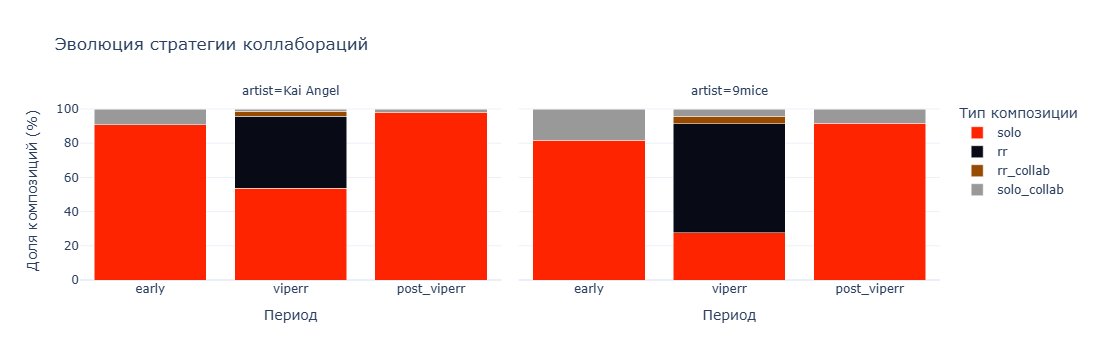

In [24]:
fig = px.bar(
    collab_stats,
    x="era",
    y="percentage",
    color="collab_type",
    facet_col="artist",
    barmode="stack",
    title="Эволюция стратегии коллабораций",
    category_orders={
        "era": ["early", "viperr", "post_viperr"],
        "artist": ["Kai Angel", "9mice"],
        "collab_type": ["solo", "rr", "rr_collab", "solo_collab"]
    },
    color_discrete_map={
        "solo": "#FF2400",
        "rr": "#080B16",
        "rr_collab": "#964B00",
        "solo_collab": "#999999"
    },
    labels={
        "era": "Период",
        "percentage": "Доля композиций (%)",
        "collab_type": "Тип композиции"
    },
    hover_data=["track_count"],
    template="plotly_white"
)

fig.show()

## 6. Анализ популярности и устойчивости в чартах

Источник: [Kworb — Spotify Chart History](https://kworb.net/spotify/), независимый агрегатор.

История чартов по артистам нужна для сопоставления названий и первичной проверки покрытия. Для сравнения стран использовали сводные таблицы **ежедневных** чартов каждой страны: сопоставимые позиции 1–200, дни в чарте и прослушивания именно в пределах чарта.

Устанавливаем библиотеку `lxml`, выполнить `%pip install lxml`.

In [25]:
from io import StringIO
from urllib.parse import urljoin
from lxml import html

chart_urls = {
    "Kai Angel": "https://kworb.net/spotify/artist/1pxLlPRiWRUBGdSOrVL4f0.html",
    "9mice": "https://kworb.net/spotify/artist/3v0qTkZvuro4johOZyIhOm.html"
}

# Ручная сверка названий между Spotify и iTunes.
title_mapping = {
    "ринопластика - surgery": "ринопластика",
    "im all blessed the fuck up": "im all blessed the f**k up"
}

if USE_SAVED_DATA and Path("spotify_charts.csv").exists():
    chart_df = pd.read_csv("spotify_charts.csv")
else:
    all_charts = []

    for artist, url in chart_urls.items():
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        response.encoding = "utf-8"

        table = pd.read_html(StringIO(response.text), match="Peak Date")[0]
        links = pd.read_html(
            StringIO(response.text), match="Peak Date", extract_links="body"
        )[0]

        table["artist"] = artist
        table["chart_url"] = links["Title"].apply(
            lambda cell: urljoin(url, cell[1]) if cell[1] else None
        )

        all_charts.append(table)
        time.sleep(1)

    chart_df = pd.concat(all_charts, ignore_index=True)

# Исправляем названия до merge(), в том числе при чтении из CSV.
chart_df["normalized_title"] = (
    chart_df["Title"].str.replace(r"^\*\s+", "", regex=True)
    .apply(normalize_title)
    .replace(title_mapping)
)

chart_df.to_csv("spotify_charts.csv", index=False, encoding="utf-8-sig")
display(chart_df.head())

,Peak Date,Title,Streams,UA,BY,LV,KZ,EE,artist,chart_url,LT,normalized_title
0,2026/09/18,andy warhol,1491593,9,4,63,178,176,Kai Angel,https://kworb.net/spotify/track/2fZUqNHa6gSskI...,NaN,andy warhol
1,2024/09/13,* Ринопластика - Surgery,1010396,27,17,161,--,--,Kai Angel,https://kworb.net/spotify/track/6dXPD2BzUrKjce...,NaN,ринопластика
2,2024/09/13,* Ice + Alabaster,602534,23,12,165,77,182,Kai Angel,https://kworb.net/spotify/track/01OCztdBtk4POw...,NaN,ice + alabaster
3,2024/09/13,* Phoenix,467728,27,15,179,126,168,Kai Angel,https://kworb.net/spotify/track/4gypp6InByEhUi...,NaN,phoenix
4,2024/12/13,Madam,255219,39,12,167,176,--,Kai Angel,https://kworb.net/spotify/track/1OKZvb7BUCqHaF...,NaN,madam


In [26]:
keys = ["artist", "normalized_title"]

# Одинаковые название и артист могут обозначать разные композиции;
# неоднозначные ключи исключаем из автоматического сопоставления.
metadata = artist_tracks.drop_duplicates(subset=keys, keep=False)

charts_merged = chart_df.merge(metadata, on=keys, how="left")
matched_charts = charts_merged[charts_merged["song_id"].notna()].copy()
unmatched_charts = charts_merged[charts_merged["song_id"].isna()].copy()

print("Записей истории чартов:", len(chart_df))
print("Найдено совпадений:", len(matched_charts))
print("Доля совпадений:", round(len(matched_charts) / len(chart_df) * 100, 2), "%")
display(unmatched_charts[["artist", "Title"]])

Записей истории чартов: 154
Найдено совпадений: 141
Доля совпадений: 91.56 %


,artist,Title
7,Kai Angel,amy
9,Kai Angel,* SPRAY
16,Kai Angel,jennifer's body
27,Kai Angel,* HELL
28,Kai Angel,metallica
38,Kai Angel,Tainted Love
67,Kai Angel,slave to the rhythm
102,9mice,* SPRAY
118,9mice,NARCOTIK
119,9mice,* HELL


### Загрузка ежедневных чартов по странам

Один цикл выполняет одинаковую операцию для всех рынков. Список `selected_countries` можно изменить, чтобы оставить, например, только Беларусь и Казахстан. Период покрытия автоматически читается со страницы каждого рынка и хранится вместе с данными.

Сохраняли отдельные CSV-кеши по странам, чтобы повторное построение графиков не требовало сетевых запросов.

In [27]:
countries = {
    "BY": "Беларусь",
    "KZ": "Казахстан",
    "UA": "Украина",
    "LV": "Латвия",
    "EE": "Эстония",
    "LT": "Литва"
}

selected_countries = ["BY", "KZ", "UA", "LV", "EE", "LT"]
# Для двух стран: selected_countries = ["BY", "KZ"]

def get_daily_charts(country_code):
    cache_file = Path(f"kworb_{country_code.lower()}_daily.csv")
    url = f"https://kworb.net/spotify/country/{country_code.lower()}_daily_totals.html"

    if USE_SAVED_DATA and cache_file.exists():
        table = pd.read_csv(cache_file)
    else:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        response.encoding = "utf-8"

        table = pd.read_html(StringIO(response.text), match="Artist and Title")[0]

        # Архивы стран начинаются и обновляются в разные даты.
        page_text = html.fromstring(response.content).text_content()
        dates = re.search(
            r"Covers charts from\s+(\d{4}/\d{2}/\d{2})\s+to\s+(\d{4}/\d{2}/\d{2})",
            page_text
        )
        if dates is None:
            raise ValueError("Не найден период покрытия архива")

        table["archive_start"] = dates.group(1)
        table["archive_end"] = dates.group(2)
        table.to_csv(cache_file, index=False, encoding="utf-8-sig")
        time.sleep(1)

    table["country_code"] = country_code
    table["country"] = countries[country_code]
    return table

all_daily = []
chart_errors = []

for country_code in selected_countries:
    try:
        table = get_daily_charts(country_code)
        all_daily.append(table)
        print(countries[country_code], "—", len(table), "записей")
    except Exception as error:
        chart_errors.append(country_code)
        print("Не удалось загрузить", country_code, ":", error)

if not all_daily:
    raise ValueError("Не удалось загрузить ни одной страны")

daily_charts = pd.concat(all_daily, ignore_index=True)
coverage = daily_charts[[
    "country", "country_code", "archive_start", "archive_end"
]].drop_duplicates()

display(coverage)
if chart_errors:
    print("В анализ не вошли:", chart_errors)

Беларусь — 4765 записей
Казахстан — 3153 записей
Украина — 6967 записей
Латвия — 9549 записей
Эстония — 8938 записей
Литва — 8930 записей


,country,country_code,archive_start,archive_end
0,Беларусь,BY,2022/02/20,2026/11/24
4765,Казахстан,KZ,2022/02/20,2026/11/24
7918,Украина,UA,2020/07/15,2026/11/24
14885,Латвия,LV,2014/08/10,2026/11/24
24434,Эстония,EE,2014/08/10,2026/11/24
33372,Литва,LT,2014/08/10,2026/11/24


### Сопоставление чартов с дискографией

Сопоставляли по нормализованному названию и первому указанному исполнителю (с учётом известных псевдонимов). Для совместных композиций переносили статистику по `song_id` на обоих участников. Одну композицию считали не более одного раза в рамках одного исполнителя и одной страны.

Треки, которые не удалось однозначно сопоставить (включая некоторые фиты с другим первым исполнителем), не считались нулевыми.

In [28]:
# Разделяем поле Artist and Title только по первому разделителю.
daily_stats = daily_charts.copy()
daily_stats[["artist", "track_title"]] = (
    daily_stats["Artist and Title"].str.split(" - ", n=1, expand=True)
)
daily_stats["artist"] = daily_stats["artist"].str.strip().str.lower().map(alias_mapping)
daily_stats = daily_stats[daily_stats["artist"].notna()].copy()

daily_stats["normalized_title"] = (
    daily_stats["track_title"].apply(normalize_title).replace(title_mapping)
)
daily_stats = daily_stats.rename(columns={
    "Days": "days_in_chart",
    "Pk": "daily_peak",
    "Total": "chart_streams"
})

for column in ["days_in_chart", "daily_peak", "chart_streams"]:
    daily_stats[column] = pd.to_numeric(daily_stats[column], errors="coerce")

daily_stats = daily_stats.dropna(subset=["days_in_chart", "daily_peak", "chart_streams"])
daily_stats = daily_stats.drop_duplicates(
    subset=["country_code"] + keys, keep=False
)

daily_matches = daily_stats.merge(metadata[keys + ["song_id"]], on=keys, how="inner")

metric_columns = [
    "song_id", "country_code", "country", "archive_start", "archive_end",
    "days_in_chart", "daily_peak", "chart_streams"
]
metrics = daily_matches[metric_columns].drop_duplicates()

# Если две строки дают разные показатели для одной композиции и страны,
# не выбираем одну из них произвольно.
metrics = metrics.drop_duplicates(subset=["song_id", "country_code"], keep=False)

stability = artist_tracks.merge(metrics, on="song_id", how="inner")
stability = stability.drop_duplicates(subset=["artist", "song_id", "country_code"])

print("Сопоставленных записей композиция × артист × страна:", len(stability))
print("Уникальных композиций:", stability["song_id"].nunique())

display(stability.groupby(["country", "artist"])["song_id"].nunique()
        .reset_index(name="track_count"))

display(stability[[
    "country", "artist", "track_name", "collab_type", "days_in_chart", "daily_peak"
]].sort_values("days_in_chart", ascending=False).head(15))

Сопоставленных записей композиция × артист × страна: 298
Уникальных композиций: 118


,country,artist,track_count
0,Беларусь,9mice,50
1,Беларусь,Kai Angel,89
2,Казахстан,9mice,5
3,Казахстан,Kai Angel,6
4,Латвия,9mice,14
5,Латвия,Kai Angel,13
6,Литва,9mice,1
7,Украина,9mice,41
8,Украина,Kai Angel,72
9,Эстония,9mice,4


,country,artist,track_name,collab_type,days_in_chart,daily_peak
234,Украина,9mice,Jealous,solo_collab,230,1
232,Беларусь,9mice,Jealous,solo_collab,230,1
62,Беларусь,Kai Angel,Ринопластика,rr,132,16
59,Беларусь,9mice,Ринопластика,rr,132,16
257,Украина,Kai Angel,andy warhol,solo,82,7
255,Беларусь,Kai Angel,andy warhol,solo,82,3
89,Беларусь,9mice,Ice + Alabaster,rr,65,4
94,Беларусь,Kai Angel,Ice + Alabaster,rr,65,4
1,Беларусь,9mice,LIPSTICK,rr,59,106
0,Беларусь,Kai Angel,LIPSTICK,rr,59,106


### Продолжительность треков и успех в ежедневных чартах

Корреляция Спирмена рассчитывалась отдельно для каждого артиста и рынка. Отрицательная корреляция означала, что более длинные треки имеют тенденцию занимать лучшие позиции (меньшие числовые ранги). Это связь, а не доказательство причинности.

,country,artist,track_count,spearman
0,Беларусь,9mice,50,-0.267
1,Беларусь,Kai Angel,89,-0.335
2,Казахстан,9mice,5,-0.100
3,Казахстан,Kai Angel,6,-0.143
4,Латвия,9mice,14,-0.209
5,Латвия,Kai Angel,13,-0.115
6,Литва,9mice,1,NaN
7,Украина,9mice,41,-0.136
8,Украина,Kai Angel,72,-0.172
9,Эстония,9mice,4,-0.800


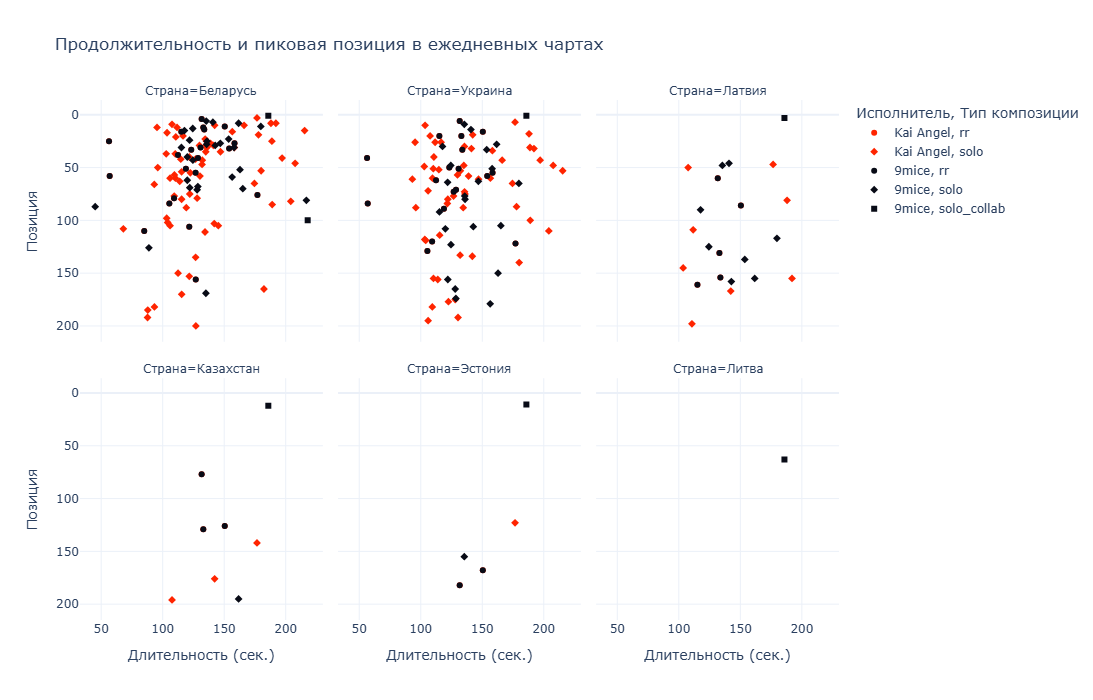

In [29]:
correlations = []

for (country, artist), group in stability.groupby(["country", "artist"]):
    rho = (
        group["duration_sec"].rank().corr(group["daily_peak"].rank())
        if len(group) >= 3 else float("nan")
    )
    correlations.append({
        "country": country,
        "artist": artist,
        "track_count": len(group),
        "spearman": round(rho, 3)
    })

correlations = pd.DataFrame(correlations)
display(correlations)

if not stability.empty:
    fig = px.scatter(
        stability, x="duration_sec", y="daily_peak",
        color="artist", symbol="collab_type", hover_name="track_name",
        facet_col="country", facet_col_wrap=3,
        color_discrete_map=artist_colors, template="plotly_white",
        title="Продолжительность и пиковая позиция в ежедневных чартах",
        labels={"duration_sec": "Длительность (сек.)", "daily_peak": "Позиция",
                "artist": "Исполнитель", "collab_type": "Тип композиции",
                "country": "Страна"},
        height=350 * ((stability["country"].nunique() + 2) // 3)
    )
    fig.update_yaxes(autorange="reversed")
    fig.show()

### Устойчивость в чартах

Доля дней в чарте = число дней в топ-200 / число дней наблюдения × 100%.

Начало наблюдения - более поздняя из дат релиза и начала архива страны. Конец - дата обновления этой страны. Если число дней превышало период наблюдения, отмечалось расхождение между метаданными и архивом; такие записи исключали **только** из нормализованной метрики, а не из исходной статистики чартов.

Расхождения дат или числа дней: 2


,country,artist,track_name,release_date,days_in_chart,days_available
232,Беларусь,9mice,Jealous,2026-04-10 12:00:00+00:00,230,229
234,Украина,9mice,Jealous,2026-04-10 12:00:00+00:00,230,229


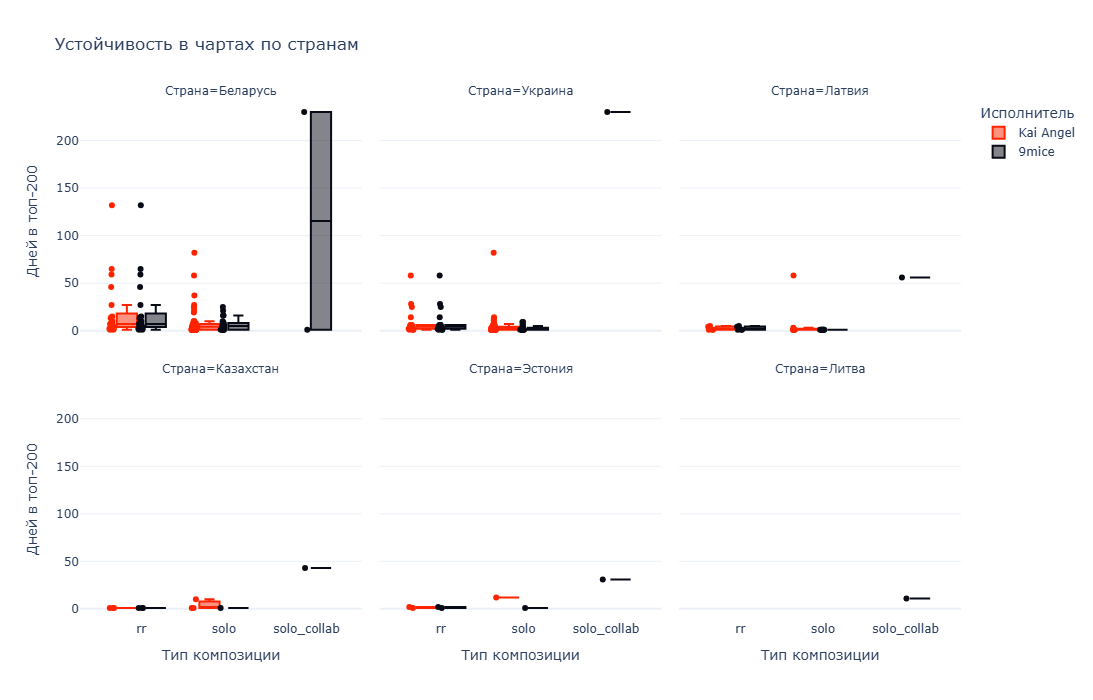

In [30]:
stability["archive_start"] = pd.to_datetime(stability["archive_start"], utc=True)
stability["archive_end"] = pd.to_datetime(stability["archive_end"], utc=True)

release_day = pd.to_datetime(stability["release_date"], utc=True).dt.normalize()
stability["observation_start"] = release_day.where(
    release_day >= stability["archive_start"], stability["archive_start"]
)

stability["days_available"] = (
    stability["archive_end"] - stability["observation_start"]
).dt.days + 1

stability["chart_share"] = (
    stability["days_in_chart"] / stability["days_available"] * 100
)

valid = (
    release_day.notna() &
    (stability["days_available"] > 0) &
    stability["chart_share"].between(0, 100)
)

stability_valid = stability[valid].copy()

print("Расхождения дат или числа дней:", (~valid).sum())
display(stability.loc[~valid, [
    "country", "artist", "track_name", "release_date", "days_in_chart", "days_available"
]])

if not stability.empty:
    fig = px.box(
        stability, x="collab_type", y="days_in_chart",
        color="artist", points="all", hover_name="track_name",
        facet_col="country", facet_col_wrap=3,
        color_discrete_map=artist_colors, template="plotly_white",
        title="Устойчивость в чартах по странам",
        labels={"collab_type": "Тип композиции", "days_in_chart": "Дней в топ-200",
                "artist": "Исполнитель", "country": "Страна"},
        height=350 * ((stability["country"].nunique() + 2) // 3)
    )
    fig.show()

### Сравнение после Viperr

Использовали календарный период с 2025 года. Сравнивали медианы и число наблюдений внутри каждого рынка, а не суммарный ранг разных стран.

,country,artist,collab_type,track_count,median_peak,median_days,median_chart_share
0,Беларусь,9mice,solo,21,28.0,5.0,1.05
1,Беларусь,9mice,solo_collab,1,100.0,1.0,0.69
2,Беларусь,Kai Angel,solo,51,37.0,5.0,1.88
3,Казахстан,9mice,solo,1,195.0,1.0,0.15
4,Казахстан,9mice,solo_collab,1,12.0,43.0,18.78
5,Казахстан,Kai Angel,solo,2,169.0,5.5,6.19
6,Латвия,9mice,solo,7,117.0,1.0,0.25
7,Латвия,9mice,solo_collab,1,3.0,56.0,24.45
8,Латвия,Kai Angel,solo,7,109.0,1.0,0.44
9,Литва,9mice,solo_collab,1,63.0,11.0,4.80


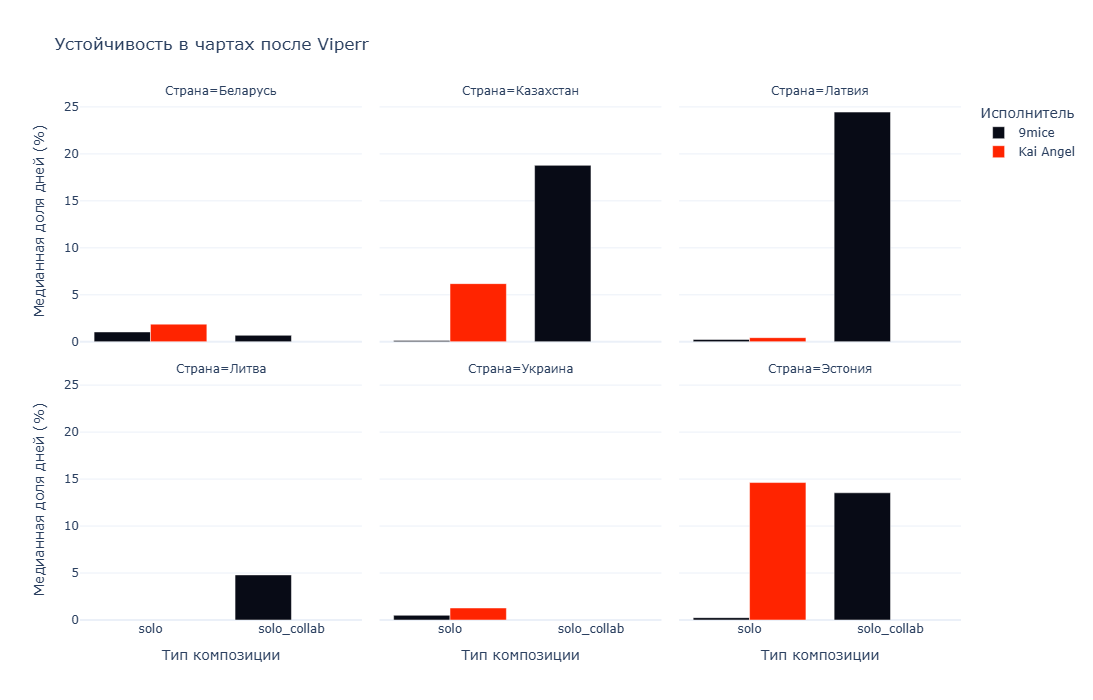

In [31]:
post_viperr = stability_valid[stability_valid["era"] == "post_viperr"]

post_summary = (
    post_viperr.groupby(["country", "artist", "collab_type"])
    .agg(
        track_count=("song_id", "nunique"),
        median_peak=("daily_peak", "median"),
        median_days=("days_in_chart", "median"),
        median_chart_share=("chart_share", "median")
    )
    .round(2).reset_index()
)

display(post_summary)

if not post_summary.empty:
    fig = px.bar(
        post_summary, x="collab_type", y="median_chart_share",
        color="artist", barmode="group",
        facet_col="country", facet_col_wrap=3,
        hover_data=["track_count", "median_days", "median_peak"],
        color_discrete_map=artist_colors, template="plotly_white",
        title="Устойчивость в чартах после Viperr",
        labels={"collab_type": "Тип композиции",
                "median_chart_share": "Медианная доля дней (%)",
                "artist": "Исполнитель", "country": "Страна"},
        height=350 * ((post_summary["country"].nunique() + 2) // 3)
    )
    fig.show()

### Общий итог по выбранным странам

**Страны** - число рынков, где композиция была найдена в топ-200. **Market-days** - сумма дней присутствия в чартах всех этих рынков (один календарный день в двух странах считается дважды). **Chart streams** - сумма прослушиваний в чартах этих стран, а не все прослушивания Spotify. Позиции не складывались.

Совместный трек представлен у обоих артистов; при анализе всех композиций вместе убирали повтор одного `song_id`. Здесь сравнивали артистов, поэтому совместные композиции учитываются в дискографии каждого.

Рынки, включённые в анализ: BY, KZ, UA, LV, EE, LT


,artist,song_id,track_name,collab_type,era,markets,market_days,chart_streams
43,9mice,1889890388,Jealous,solo_collab,post_viperr,6,601,3887813
120,Kai Angel,6808163353,andy warhol,solo,post_viperr,5,244,1491593
9,9mice,1767963491,Ринопластика,rr,viperr,3,191,983785
70,Kai Angel,1767963491,Ринопластика,rr,viperr,3,191,983785
15,9mice,1767963932,Ice + Alabaster,rr,viperr,5,100,602534
76,Kai Angel,1767963932,Ice + Alabaster,rr,viperr,5,100,602534
68,Kai Angel,1767963484,Phoenix,rr,viperr,5,78,467728
7,9mice,1767963484,Phoenix,rr,viperr,5,78,467728
122,Kai Angel,6808163586,BABYLON,solo,post_viperr,2,67,164503
44,9mice,1889978893,LIPSTICK,rr,viperr,1,59,105068


,artist,collab_type,track_count,median_markets,median_market_days,median_chart_streams
0,9mice,solo,21,2.0,6.0,22367.0
1,9mice,solo_collab,2,3.5,301.0,1944787.5
2,Kai Angel,solo,51,2.0,7.0,22581.0


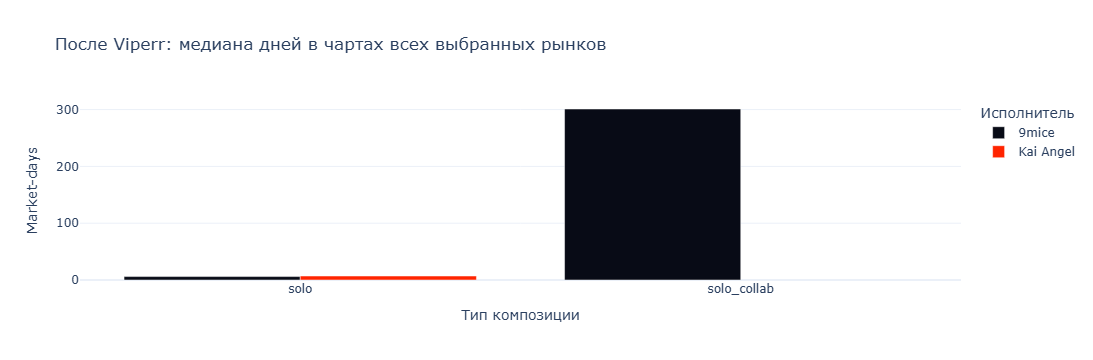

In [32]:
all_markets = (
    stability.groupby(["artist", "song_id", "track_name", "collab_type", "era"])
    .agg(
        markets=("country_code", "nunique"),
        market_days=("days_in_chart", "sum"),
        chart_streams=("chart_streams", "sum")
    )
    .reset_index()
)

print("Рынки, включённые в анализ:", ", ".join(coverage["country_code"]))
display(all_markets.sort_values("market_days", ascending=False).head(20))

combined_post = (
    all_markets[all_markets["era"] == "post_viperr"]
    .groupby(["artist", "collab_type"])
    .agg(
        track_count=("song_id", "nunique"),
        median_markets=("markets", "median"),
        median_market_days=("market_days", "median"),
        median_chart_streams=("chart_streams", "median")
    )
    .round(2).reset_index()
)
display(combined_post)

if not combined_post.empty:
    fig = px.bar(
        combined_post, x="collab_type", y="median_market_days",
        color="artist", barmode="group",
        hover_data=["track_count", "median_markets", "median_chart_streams"],
        color_discrete_map=artist_colors, template="plotly_white",
        title="После Viperr: медиана дней в чартах всех выбранных рынков",
        labels={"collab_type": "Тип композиции", "median_market_days": "Market-days",
                "artist": "Исполнитель"}
    )
    fig.show()

stability.to_csv("charts_by_country.csv", index=False, encoding="utf-8-sig")
all_markets.to_csv("charts_all_markets.csv", index=False, encoding="utf-8-sig")
correlations.to_csv("chart_correlations.csv", index=False, encoding="utf-8-sig")
post_summary.to_csv("post_viperr_by_country.csv", index=False, encoding="utf-8-sig")

## 7. Предварительные выводы по дискографии

1. После очистки дискографии получена 221 уникальная композиция. С ежедневными чартами шести стран удалось сопоставить 118 композиций (298 записей «композиция × артист × страна»).
2. В GOD SYSTEM 11 из 17 треков короче двух минут. Сравнение альбомов не показывает постоянного сокращения длительности треков.
3. В Беларуси и Украине корреляция Спирмена между продолжительностью трека и пиковой числовой позицией отрицательна у обоих артистов (от −0,136 до −0,335). Более длинные треки имеют тенденцию занимать лучшие позиции, но связь невелика. Гипотеза о преимуществе коротких композиций не получила подтверждения :)
4. В период с 2025 года в чартах сопоставлена 51 сольная композиция Kai Angel и 21 сольная композиция 9mice. Медианная устойчивость сольных треков по всем рынкам близка: 7 и 6 market-days соответственно.
5. Наибольшая суммарная устойчивость у 9mice у коллаборации *Jealous* (601 market-days, шесть стран, первое место в Беларуси и Украине). У Kai Angel у сольного трека *andy warhol* (244 market-days, пять стран). Выборка сопоставленных коллабораций 9mice после 2024 года состоит всего из двух композиций, поэтому нельзя обобщать результат на все его фиты.
6. Первоначальные гипотезы подтвердились частично. Данные позволяют сравнить релизную активность и чартовые результаты, но не установить причинность или оценить всё творчество артистов.

## 8. Ограничения

- Каталог iTunes US может не содержать всех ранних релизов, альбомов и фитов.
- Даты iTunes могут относиться к переизданиям или отличаться от дат Spotify. В двух строках Jealous расхождение между доступным временем и днями в чарте составило один день; они исключены из расчёта нормированной доли дней.
- Сопоставление по названиям и участникам может пропустить отдельные треки. Отсутствие совпадения не считается нулём.
- Архивы стран имеют разную глубину. Дни и прослушивания учитывают только присутствие в топ-200, а market-days суммируются по странам.
- Размеры групп отличаются, а у новых релизов меньше времени для накопления чартовых показателей. В нескольких странах выборки слишком малы для надёжных выводов.
- Тексты, биты и инфоповоды не анализировались.